# interpretation of the first function expo (x) with 3 methode(lagrange , newton , hermite)

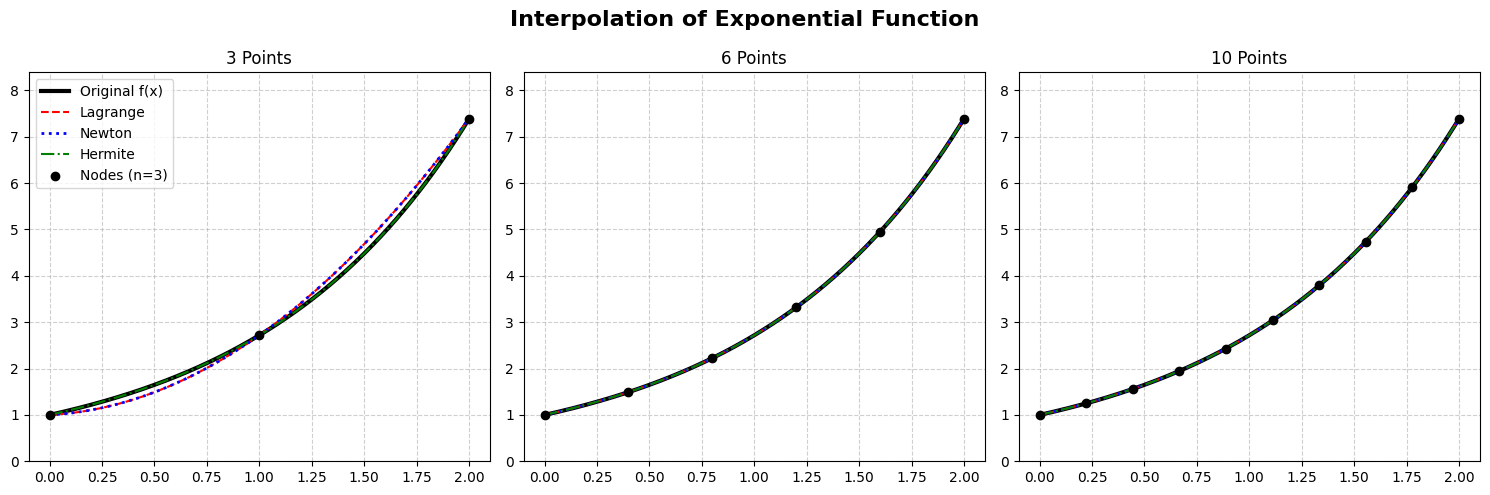

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import lagrange, KroghInterpolator

def exp(x):
    return np.exp(x)

def d_exp(x):
    return np.exp(x)  #derive de expo x

def sin(x):
    return np.sin(x)

def d_sin(x):
    return np.cos(x)  #derive de sin x 


def newton_divided_dif(x_n,y_n):
    n =len(x_n)
    coeff = np.zeros([n,n])
    coeff[: , 0]=y_n

    for j in range(1, n):
       for i in range(n - j):
         coeff[i][j] = (coeff[i+1][j-1] - coeff[i][j-1]) / (x_n[i+j] - x_n[i])
    return coeff[0, :]
    

def evaluate_newton(x_n, y_n, x_evl):
    coeff = newton_divided_dif(x_n, y_n)
    n = len(x_n)
    p=  np.zeros(len(x_evl))

    for k in range(len(x_evl)):
        val = coeff[n-1]
        for i in range(n-2, -1, -1):
            val = val * (x_evl[k] - x_n[i]) + coeff[i]
        p[k] = val
    return p


def compar_interpol(func, d_func, title, x_str, x_end):
    point_counts = [3, 6, 10]
    x_dense = np.linspace(x_str, x_end, 500)
    y_true = func(x_dense)
    plt.figure(figsize=(15, 5))
    plt.suptitle(f"Interpolation of {title}", fontsize=16, fontweight='bold')

    for i, n in enumerate(point_counts):
        plt.subplot(1, 3, i + 1)
        
        # Generate our known data nodes
        x_nodes = np.linspace(x_str, x_end, n)
        y_nodes = func(x_nodes)
        dy_nodes = d_func(x_nodes)

        # A) Lagrange Polynomial (Using SciPy)
        poly_lagrange = lagrange(x_nodes, y_nodes)
        y_lagrange = poly_lagrange(x_dense)

        # B) Newton Polynomial (Using our custom function)
        y_newton = evaluate_newton(x_nodes, y_nodes, x_dense)

        # C) Hermite Polynomial (Using SciPy's KroghInterpolator)
        x_hermite = np.repeat(x_nodes, 2)
        y_hermite = np.zeros_like(x_hermite)
        y_hermite[0::2] = y_nodes     
        y_hermite[1::2] = dy_nodes     
        
        poly_hermite = KroghInterpolator(x_hermite, y_hermite)
        y_hermite_eval = poly_hermite(x_dense)

        # Plotting
        plt.plot(x_dense, y_true, 'k-', linewidth=3, label="Original f(x)")
        plt.plot(x_dense, y_lagrange, 'r--', label="Lagrange")
        plt.plot(x_dense, y_newton, 'b:', linewidth=2, label="Newton")
        plt.plot(x_dense, y_hermite_eval, 'g-.', label="Hermite")
        plt.scatter(x_nodes, y_nodes, color='black', zorder=5, label=f"Nodes (n={n})")

        plt.title(f"{n} Points")
        plt.ylim(min(y_true) - 1, max(y_true) + 1)
        plt.grid(True, linestyle='--', alpha=0.6)
        if i == 0:
            plt.legend()

    plt.tight_layout()
    plt.show()

compar_interpol(exp, d_exp, "Exponential Function", 0, 2)





# interpretation of the seconde function sin(x) with 3 methode(lagrange , newton , hermite)

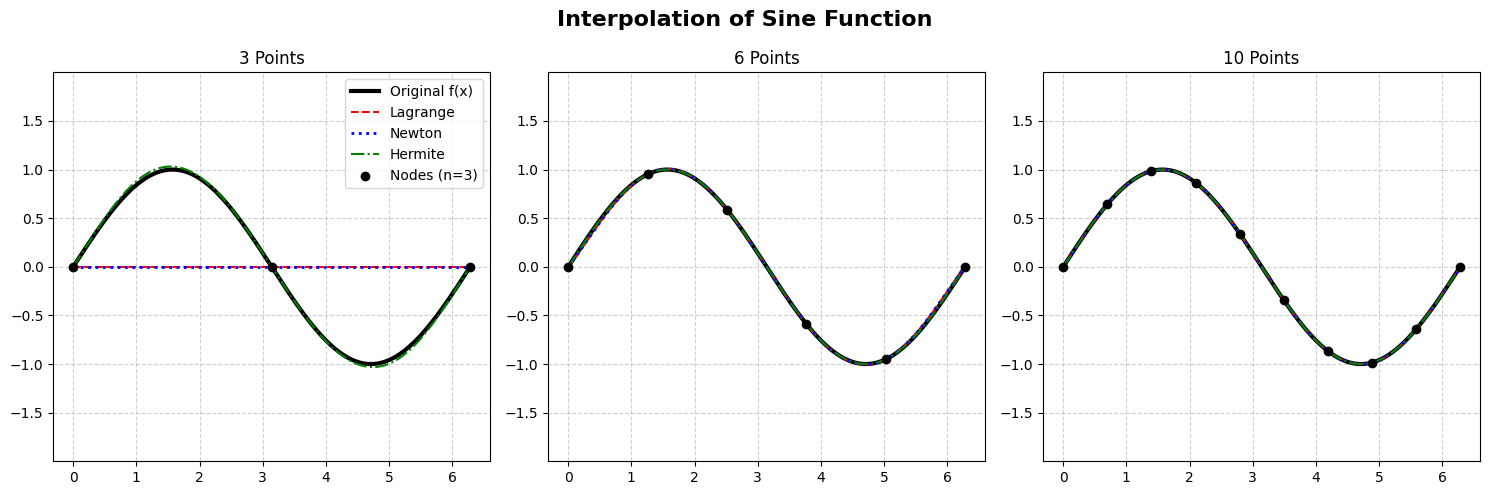

In [4]:
compar_interpol(sin, d_sin, "Sine Function", 0, 2 * np.pi)  